In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("PS_20174392719_1491204439457_log.csv")

df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [2]:
df.shape
df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [3]:
# Most common transaction types

transaction_type_count = df['type'].value_counts()

print(transaction_type_count)

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


In [4]:
# Most common transaction types by percentage

transaction_type_percentage = (df['type'].value_counts(normalize=True*100).round(2))

print(transaction_type_percentage)

type
CASH_OUT    0.35
PAYMENT     0.34
CASH_IN     0.22
TRANSFER    0.08
DEBIT       0.01
Name: proportion, dtype: float64


For the most common transaction type, CASH_OUT was the most common transaction type, followed by PAYMENT, while DEBIT is the smallest 

In [5]:
# Average by Transaction type

average_by_type = (df.groupby('type')['amount']
                   .mean()
                   .sort_values(ascending=False))

print(average_by_type)

type
TRANSFER    910647.009645
CASH_OUT    176273.964346
CASH_IN     168920.242004
PAYMENT      13057.604660
DEBIT         5483.665314
Name: amount, dtype: float64


In [6]:
# Transaction Frequency

customer_frequency = (
    df.groupby('nameOrig')
    .size()
    .reset_index(name='transaction_frequency')
)

print(customer_frequency.head())

      nameOrig  transaction_frequency
0  C1000000639                      1
1  C1000001337                      1
2  C1000001725                      1
3  C1000002591                      1
4  C1000003372                      1


In [7]:
# Average Customer Frequency

customer_frequency['transaction_frequency'].mean()

np.float64(1.0014658507766112)

Transaction Hours

In [8]:
df['hour'] =df['step'] % 24

In [9]:
hourly_transactions = (
    df.groupby('hour')
    .size()
    .reset_index(name='transaction_count')
)

print(hourly_transactions)

    hour  transaction_count
0      0              71587
1      1              27111
2      2               9018
3      3               2007
4      4               1241
5      5               1641
6      6               3420
7      7               8988
8      8              26915
9      9             283518
10    10             425729
11    11             445992
12    12             483418
13    13             468474
14    14             439653
15    15             416686
16    16             441612
17    17             439941
18    18             580509
19    19             647814
20    20             553728
21    21             247806
22    22             194555
23    23             141257


In [10]:
# Peak hour of transaction

peak_hour = hourly_transactions.loc[
    hourly_transactions['transaction_count'].idxmax()
]

print(peak_hour)

hour                     19
transaction_count    647814
Name: 19, dtype: int64


In [11]:
# customer balance trends

df['origin_balance_change'] = (
    df['newbalanceOrig'] - df['oldbalanceOrg']
)

In [12]:
# Originator Balance change

df['origin_balance_change'] = (
    df['newbalanceOrig'] - df['oldbalanceOrg']
)

In [13]:
# Recipient Balance Change

df['destination_balance_change'] = (
    df['newbalanceDest'] - df['oldbalanceDest']
)

In [14]:
balance_by_type = (
    df.groupby('type')[
        ['origin_balance_change',
         'destination_balance_change']
    ]
    .mean()
)

print(balance_by_type)

          origin_balance_change  destination_balance_change
type                                                       
CASH_IN           168915.203779              -120813.411259
CASH_OUT          -28549.612057               193568.180775
DEBIT              -3485.685163                19867.696753
PAYMENT            -6378.936662                    0.000000
TRANSFER          -44153.695021               986961.106232


Customer Segmentation

In [15]:
# Transaction Frequency

customer_features = (
    df.groupby('nameOrig')
    .agg(
        transaction_frequency=('amount', 'count'),
        average_transaction_amount=('amount', 'mean'),
        total_transaction_amount=('amount','sum'),
        average_balance=('oldbalanceOrg', 'mean'),
        total_balance_change=('origin_balance_change', 'sum')
    )
    .reset_index()
)

customer_features.head()

,nameOrig,transaction_frequency,average_transaction_amount,total_transaction_amount,average_balance,total_balance_change
0,C1000000639,1,244486.46,244486.46,8946.00,-8946.00
1,C1000001337,1,3170.28,3170.28,58089.00,-3170.28
2,C1000001725,1,8424.74,8424.74,783.00,-783.00
3,C1000002591,1,261877.19,261877.19,7596.00,261877.19
4,C1000003372,1,20528.65,20528.65,2302074.12,20528.65


In [16]:
# Customer's Preferred Transaction type

preferred_type = (
    df.groupby(['nameOrig', 'type'])
    .size()
    .reset_index(name='count')
)
preferred_type.head(10)

,nameOrig,type,count
0,C1000000639,CASH_OUT,1
1,C1000001337,PAYMENT,1
2,C1000001725,PAYMENT,1
3,C1000002591,CASH_IN,1
4,C1000003372,CASH_IN,1
5,C1000003615,CASH_IN,1
6,C1000004053,CASH_OUT,1
7,C1000004530,CASH_OUT,1
8,C1000005353,TRANSFER,1
9,C1000005555,CASH_OUT,1


In [17]:
preferred_type = preferred_type.loc[
    preferred_type.groupby('nameOrig')['count'].idxmax()
]
preferred_type = preferred_type[
    ['nameOrig', 'type']
].rename(
    columns={'type': 'preferred_transaction_type'}
)

preferred_type.head(10)

,nameOrig,preferred_transaction_type
0,C1000000639,CASH_OUT
1,C1000001337,PAYMENT
2,C1000001725,PAYMENT
3,C1000002591,CASH_IN
4,C1000003372,CASH_IN
5,C1000003615,CASH_IN
6,C1000004053,CASH_OUT
7,C1000004530,CASH_OUT
8,C1000005353,TRANSFER
9,C1000005555,CASH_OUT


In [18]:
customer_features = customer_features.merge(
    preferred_type,
    on='nameOrig',
    how='left'
)

customer_features.head(10)

,nameOrig,transaction_frequency,average_transaction_amount,total_transaction_amount,average_balance,total_balance_change,preferred_transaction_type
0,C1000000639,1,244486.46,244486.46,8946.00,-8946.00,CASH_OUT
1,C1000001337,1,3170.28,3170.28,58089.00,-3170.28,PAYMENT
2,C1000001725,1,8424.74,8424.74,783.00,-783.00,PAYMENT
3,C1000002591,1,261877.19,261877.19,7596.00,261877.19,CASH_IN
4,C1000003372,1,20528.65,20528.65,2302074.12,20528.65,CASH_IN
5,C1000003615,1,49360.77,49360.77,1472658.31,49360.76,CASH_IN
6,C1000004053,1,211189.64,211189.64,0.00,0.00,CASH_OUT
7,C1000004530,1,93865.13,93865.13,351422.72,-93865.13,CASH_OUT
8,C1000005353,1,3228390.11,3228390.11,24996.00,-24996.00,TRANSFER
9,C1000005555,1,233109.79,233109.79,20623.00,-20623.00,CASH_OUT


In [45]:
customer_features.groupby('segment').agg(
    customers=('nameOrig', 'count'),
    avg_frequency=('transaction_frequency', 'mean'),
    avg_transaction_amount=('average_transaction_amount', 'mean'),
    avg_balance=('average_balance', 'mean')
).round(2)

,customers,avg_frequency,avg_transaction_amount,avg_balance
segment,,,,
0,6027561,1.0,162598.23,280359.56
1,9293,2.0,175192.06,815421.04
2,9912,1.0,11305281.91,743150.46
3,306541,1.0,159621.50,11721952.05


In [46]:
customer_features['segment'].value_counts()

segment
0    6027561
3     306541
2       9912
1       9293
Name: count, dtype: int64

In [20]:
# Customer Activity Based on Transaction Frequency

customer_features['activity_level'] = pd.cut(
    customer_features['transaction_frequency'],
    bins=[0, 1, 5, 10, np.inf],
    labels=['Low', 'Medium', 'High', 'Very High']
)

customer_features.head(10)

customer_features['activity_level'].value_counts().sort_index()

activity_level
Low          6344009
Medium          9298
High               0
Very High          0
Name: count, dtype: int64

In [21]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [22]:
import sys
print(sys.version)
print(sys.executable)

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
c:\Users\DELL\AppData\Local\Programs\Python\Python312\python.exe


In [23]:
import sys
!{sys.executable} -m pip --version

pip 26.2.1 from c:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\pip (python 3.12)



In [24]:
import sys
!{sys.executable} -m pip install --upgrade pip
!{sys.executable} -m pip install scikit-learn

In [25]:
# Customer Segmentation

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [26]:
features = [
    'transaction_frequency',
    'average_transaction_amount',
    'total_transaction_amount',
    'average_balance'
]

In [27]:
X = customer_features[features].fillna(0)

In [28]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [29]:
inertia = []

for k in range(2, 8):
    kmeans =KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

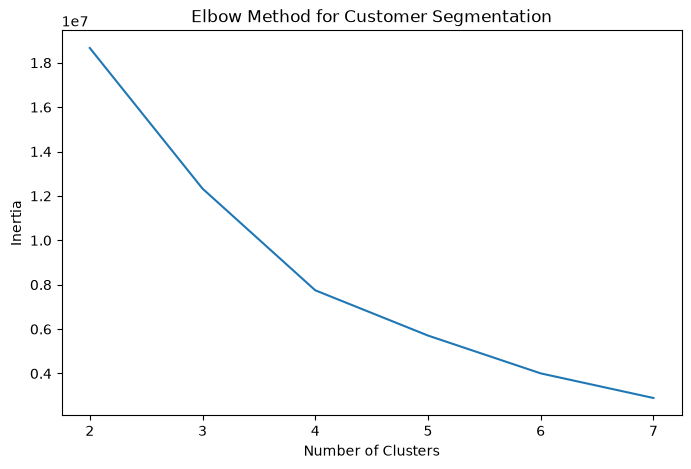

Number of cluster values: 6
Number of inertia values: 6
[18664936.435531892, 12328858.615476528, 7747659.756225405, 5708548.219230272, 4004651.0328987716, 2895292.843812567]


In [30]:
plt.figure(figsize=(8,5))

plt.plot(range(2,8), inertia)

plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method for Customer Segmentation')

plt.show()

print("Number of cluster values:", len(range(2,8)))
print("Number of inertia values:", len(inertia))
print(inertia)

In [31]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

customer_features['segment'] = kmeans.fit_predict(X_scaled)

In [32]:
segment_profile = (
    customer_features
    .groupby('segment')
    [features]
    .mean()
    .round(2)
)

print(segment_profile)

         transaction_frequency  average_transaction_amount  \
segment                                                      
0                          1.0                   162598.23   
1                          2.0                   175192.06   
2                          1.0                 11305281.91   
3                          1.0                   159621.50   

         total_transaction_amount  average_balance  
segment                                             
0                       162598.23        280359.56  
1                       350647.07        815421.04  
2                     11312864.67        743150.46  
3                       159621.50      11721952.05  


In [33]:
segment_size = (
    customer_features['segment']
    .value_counts()
    .sort_index()
)

print(segment_size)

segment
0    6027561
1       9293
2       9912
3     306541
Name: count, dtype: int64


In [34]:
# Transaction volume by hour

hourly_volume = (
    df.groupby('hour')
    .size()
    .reset_index(name='transaction_volume')
)

hourly_volume.head(10)

,hour,transaction_volume
0,0,71587
1,1,27111
2,2,9018
3,3,2007
4,4,1241
5,5,1641
6,6,3420
7,7,8988
8,8,26915
9,9,283518


In [35]:
hourly_volume.sort_values(
    'transaction_volume',
    ascending=False
).head(10)

,hour,transaction_volume
19,19,647814
18,18,580509
20,20,553728
12,12,483418
13,13,468474
11,11,445992
16,16,441612
17,17,439941
14,14,439653
10,10,425729


In [36]:
# Transaction Volumeover time

time_volume = (
    df.groupby('step')
    .size()
    .reset_index(name='transaction_volume')
)

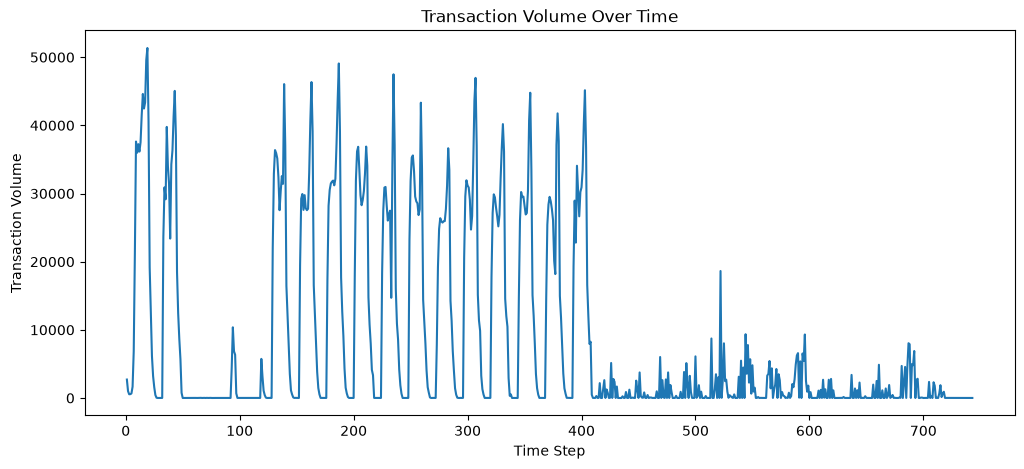

In [37]:
plt.figure(figsize=(12,5))

plt.plot(
    time_volume['step'],
    time_volume['transaction_volume']
)

plt.xlabel('Time Step')
plt.ylabel('Transaction Volume')
plt.title('Transaction Volume Over Time')

plt.show()

In [38]:
# Transaction Amount Over Time

time_amount = (
    df.groupby('step')['amount']
    .sum()
    .reset_index()
)

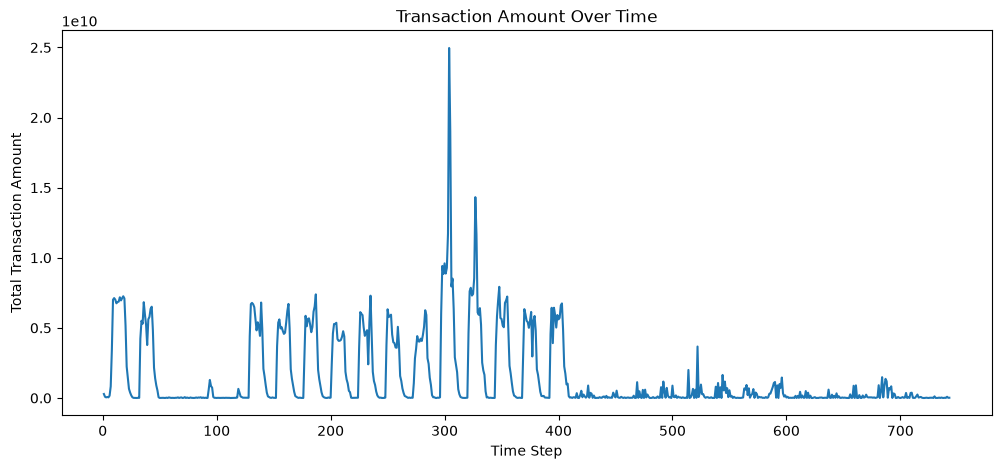

In [39]:
plt.figure(figsize=(12,5))

plt.plot(
    time_amount['step'],
    time_amount['amount']
)

plt.xlabel('Time Step')
plt.ylabel('Total Transaction Amount')
plt.title('Transaction Amount Over Time')

plt.show()

In [40]:
# Average Transaction Volume

average_volume = time_volume['transaction_volume'].mean()

print("Average transaction volume:", average_volume)

Average transaction volume: 8563.418573351279


In [41]:
peak_periods = time_volume[
    time_volume['transaction_volume'] > average_volume
]

print(peak_periods)

     step  transaction_volume
7       8               21097
8       9               37628
9      10               35991
10     11               37241
11     12               36153
..    ...                 ...
405   406               12023
513   514                8733
521   522               18631
543   544                9358
595   596                9319

[205 rows x 2 columns]


In [42]:
threshold = time_volume['transaction_volume'].quantile(0.90)

peak_periods = time_volume[
    time_volume['transaction_volume'] >= threshold
]

print(peak_periods)

     step  transaction_volume
8       9               37628
9      10               35991
10     11               37241
11     12               36153
12     13               37515
..    ...                 ...
395   396               34075
400   401               33468
401   402               40218
402   403               45155
403   404               36726

[75 rows x 2 columns]


In [43]:
# Transaction type by distribution


type_distribution = (
    df.groupby('type')
    .agg(
        transaction_count=('amount', 'count'),
        total_amount=('amount', 'sum'),
        average_amount=('amount', 'mean')
    )
    .reset_index()
)

type_distribution['percentage'] = (
    type_distribution['transaction_count']
    / type_distribution['transaction_count'].sum()
    * 100
)

print(type_distribution)

       type  transaction_count  total_amount  average_amount  percentage
0   CASH_IN            1399284  2.363674e+11   168920.242004   21.992261
1  CASH_OUT            2237500  3.944130e+11   176273.964346   35.166331
2     DEBIT              41432  2.271992e+08     5483.665314    0.651178
3   PAYMENT            2151495  2.809337e+10    13057.604660   33.814608
4  TRANSFER             532909  4.852920e+11   910647.009645    8.375622


In [44]:
customer_features.to_csv(
    'customer_features.csv',
    index=False
)